# Part C — Model Evaluation and Interpretation

**Research Question:** Can we predict the winning team in a League of Legends match using only statistics available after the first 10 minutes?

This notebook presents the completed independent evaluation of four frozen Part B models on the original Diamond dataset (9,879 matches). The original stratified split contains 7,903 training matches and 1,976 held-out matches. Blue wins (`blueWins=1`) is the positive class.

**Current stage: final evaluation complete.** The authorized evaluation was executed once. All cells below read saved aggregate evidence and figures; they cannot train models, load match records, or repeat held-out predictions. The SVM selected through nested cross-validation remains the main model.

## 1. Reproduction and evaluation status

Use Python 3.11 and the existing dependencies in `requirements-part-b.txt`. Preliminary tests and numerical verification were completed before the authorized final evaluation. The final workflow is now complete and must not be rerun for inference.

To regenerate the figures and report from saved evidence, use `.venv/bin/python -B scripts/evaluate_models.py --render-saved-results`. Then execute this notebook with `.venv/bin/python -B scripts/execute_evaluation_notebook.py`. Both operations reuse saved results. Tests can be rerun independently with the Part C unittest command documented in `README_PART_C.md`.

In [1]:
from pathlib import Path
import os
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "src/lol_model_evaluation.py").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lol_model_evaluation import load_saved_evaluation, output_paths, MODEL_DISPLAY_NAMES
from src.lol_model_training import load_run_results

RUN_ID = os.environ.get("LOL_PART_C_RUN_ID", "diamond_5x3_seed42")
saved = load_saved_evaluation(root=ROOT, run_id=RUN_ID)
training = load_run_results(ROOT, RUN_ID)
paths = output_paths(ROOT, RUN_ID)
if saved["metadata"]["status"] not in {"awaiting_authorization", "complete"}:
    raise RuntimeError("Evaluation is incomplete. Inspect its saved state before interpreting results.")
complete = saved["metadata"]["status"] == "complete"
display(pd.DataFrame([{
    "Training run": RUN_ID,
    "Evaluation status": saved["metadata"]["status"],
    "Preselected model": "Linear SVM (C=10)",
    "Positive class": "Blue wins (1)",
    "Held-out predictions computed": saved["metadata"]["held_out_predictions_computed"],
}]))

,Training run,Evaluation status,Preselected model,Positive class,Held-out predictions computed
0,diamond_5x3_seed42,complete,Linear SVM (C=10),Blue wins (1),True


## 2. Frozen protocol and compatibility

Part A uses 12 unscaled Blue-minus-Red features in a fixed order. Match identifiers are row indices, never predictors. The split is stratified with `test_size=0.20`, `random_state=42`, and ascending `gameId` ordering before splitting.

Part B used nested stratified CV with five outer and three inner folds. It selected SVM using mean outer-fold accuracy, then tuned each family on the full training set. The saved SVM is linear with `C=10`. KNN and SVM contain their already fitted StandardScaler; test features must enter these pipelines unscaled.

Accuracy remains the primary metric. No result in this notebook may reopen family selection, feature engineering, tuning, or threshold optimization. The preflight verifies source and artifact checksums, original split membership, CV membership, environment, feature order, classes, and saved hyperparameters.

In [2]:
preflight = saved["preflight"]
display(pd.DataFrame([{
    "Preflight status": preflight["status"],
    "Training matches": preflight["training_rows"],
    "Held-out matches": preflight["held_out_rows"],
    "Held-out values accessed during preflight": preflight["held_out_values_accessed"],
    "Source access": preflight["source_access"],
    "Automatic tests passed": preflight["automatic_tests"]["successful"],
    "Automatic tests executed": preflight["automatic_tests"]["tests_run"],
}]))
display(pd.DataFrame({"Column position": range(1, 13), "Feature": preflight["feature_names"]}))
display(pd.DataFrame.from_dict(preflight["artifacts"], orient="index").rename_axis("Model"))

,Preflight status,Training matches,Held-out matches,Held-out values accessed during preflight,Source access,Automatic tests passed,Automatic tests executed
0,passed,7903,1976,False,Byte-level checksum only; CSV not parsed,True,31


,Column position,Feature
0,1,blueGoldDiff
1,2,blueExperienceDiff
2,3,killsDiff
3,4,assistsDiff
4,5,minionsDiff
5,6,jungleMinionsDiff
6,7,wardsPlacedDiff
7,8,wardsDestroyedDiff
8,9,firstBloodDiff
9,10,dragonsDiff


,checksum_verified,hyperparameters_verified,schema_verified
Model,,,
decision_tree,True,True,True
dummy,True,True,True
knn,True,True,True
svm,True,True,True


## 3. Numerical reliability of the linear SVM

For a binary linear SVC with class order `[0,1]`, the primal coefficients in standardized coordinates are

$$w_j=\sum_i (y_i\alpha_i)\,SV_{ij}.$$

Here the internal SVM labels in the formula are encoded as -1 and +1, while the dataset target remains 0/1. The stored dual coefficients already include these signs. The signed dual coefficients and support vectors are already stored in the model. Part C reconstructs each coefficient with `math.fsum`, reducing cancellation when thousands of signed products are summed. This operation does not refit or modify the estimator.

On this machine, reading `SVC.coef_` emits floating-point warnings in a NumPy matrix multiplication. Diagnostics retain the warning messages and compare NumPy `matmul`, NumPy `dot`, and the independent reconstruction. The evidence isolates the warning path; it does not establish a specific hardware or low-level library defect.

An independent check compares the reconstructed scores with the saved pipeline's `decision_function` on 539 artificial points: the training mean, positive and negative coordinate directions, 512 bounded random vectors, and two larger vectors. Artificial inputs are algebraic probes and need not represent feasible matches. No held-out match is used. Tolerances are fixed before evaluation: coefficient `atol=1e-8`, score `atol=1e-7`, and `rtol=1e-8`.

In [3]:
numerical = preflight["svm_numerical_verification"]
display(pd.DataFrame([{
    "Status": numerical["status"],
    "Artificial observations": numerical["synthetic_observations"],
    "Coefficients finite": numerical["coefficients_finite"],
    "Public coefficient maximum absolute error": numerical["public_coef_maximum_absolute_error"],
    "Standardized score maximum absolute error": numerical["standardized_score_maximum_absolute_error"],
    "Original-unit score maximum absolute error": numerical["original_unit_score_maximum_absolute_error"],
    "Score absolute tolerance": numerical["score_atol"],
    "Relative tolerance": numerical["rtol"],
}]))
print("Recorded SVC.coef_ warnings:")
for message in numerical["public_coef_warnings"]:
    print("-", message)
print(numerical["diagnosis"])
display(pd.DataFrame.from_dict(numerical["multiplication_paths"], orient="index"))

,Status,Artificial observations,Coefficients finite,Public coefficient maximum absolute error,Standardized score maximum absolute error,Original-unit score maximum absolute error,Score absolute tolerance,Relative tolerance
0,passed,539,True,1.268279e-11,2.536993e-11,2.537037e-11,1.000000e-07,1.000000e-08


Recorded SVC.coef_ warnings:
- divide by zero encountered in matmul
- overflow encountered in matmul
- invalid value encountered in matmul
Warnings were checked separately for SVC.coef_, NumPy matmul, and NumPy dot. The local warning is isolated to the matmul path used by SVC.coef_; a low-level library or hardware cause has not been established. Finite weights and agreement with libsvm decision_function are independently verified. Interpretation uses math.fsum, without altering the saved model or suppressing global warnings.


,maximum_absolute_error,warnings
numpy_dot,1.268279e-11,[]
numpy_matmul,1.268279e-11,"[divide by zero encountered in matmul, overflo..."


## 4. Metrics and the positive class

The frozen estimator's `predict` method supplies class predictions. For ROC analysis, the SVM supplies continuous decision margins; Dummy, Decision Tree, and KNN supply probabilities for the column explicitly associated with class `1`.

- **Accuracy:** $(TP+TN)/N$, the proportion of all match winners correctly predicted.
- **Precision:** $TP/(TP+FP)$, the proportion of predicted Blue wins that are correct.
- **Recall:** $TP/(TP+FN)$, the proportion of actual Blue wins correctly identified.
- **F1:** $2TP/(2TP+FP+FN)$, balancing Blue precision and recall.
- **ROC-AUC:** ranking performance across thresholds; it is not the probability that a particular team wins.

Precision and F1 are zero when no positive predictions occur (`zero_division=0`), consistently with Part B. ROC-AUC requires both real classes; a one-class input is rejected rather than assigned an invented value. Synthetic examples verify the formulas, ranking ties, class order, empty inputs, and invalid scores.

In [4]:
if complete:
    metric_order = ["accuracy", "precision", "recall", "f1", "roc_auc"]
    model_order = ["dummy", "decision_tree", "knn", "svm"]
    table = pd.DataFrame.from_dict(saved["metrics"], orient="index").loc[model_order, metric_order]
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(table.rename(index=MODEL_DISPLAY_NAMES).rename_axis("Model").rename(columns={
            "accuracy": "Test accuracy", "precision": "Blue precision",
            "recall": "Blue recall", "f1": "Blue F1", "roc_auc": "Test ROC-AUC",
        }))
    svm, dummy = saved["metrics"]["svm"], saved["metrics"]["dummy"]
    display(Markdown(
        f"The preselected SVM achieves **{svm['accuracy']:.2%} accuracy**, compared with "
        f"**{dummy['accuracy']:.2%}** for the majority-class baseline: a gain of "
        f"**{100 * (svm['accuracy'] - dummy['accuracy']):.2f} percentage points**. "
        f"Its Blue precision is {svm['precision']:.4f}, recall {svm['recall']:.4f}, "
        f"and F1 {svm['f1']:.4f}. The learned models all improve on Dummy, "
        "but no statistical superiority claim follows from this descriptive comparison. "
        "The SVM remains the family chosen before inspecting test outcomes."
    ))
else:
    display(Markdown("**Pending final evaluation.** No test metrics are available."))

,Test accuracy,Blue precision,Blue recall,Blue F1,Test ROC-AUC
Model,,,,,
Dummy (baseline),0.5010,0.0000,0.0000,0.0000,0.5000
Decision Tree,0.7277,0.7398,0.7008,0.7198,0.7994
KNN,0.7262,0.7263,0.7241,0.7252,0.8081
SVM,0.7358,0.7427,0.7201,0.7312,0.8149


The preselected SVM achieves **73.58% accuracy**, compared with **50.10%** for the majority-class baseline: a gain of **23.48 percentage points**. Its Blue precision is 0.7427, recall 0.7201, and F1 0.7312. The learned models all improve on Dummy, but no statistical superiority claim follows from this descriptive comparison. The SVM remains the family chosen before inspecting test outcomes.

## 5. Confusion matrices and error interpretation

Rows represent the actual outcome and columns the prediction, both ordered `[Red (0), Blue (1)]`. The matrix is `[[TN, FP], [FN, TP]]`.

- **TN:** a Red win correctly predicted as Red.
- **FP:** a Red win incorrectly predicted as Blue.
- **FN:** a Blue win incorrectly predicted as Red.
- **TP:** a Blue win correctly predicted as Blue.

Each final matrix must contain exactly 1,976 matches. The implementation independently reconstructs accuracy, precision, recall, and F1 from these counts to check orientation and consistency. The four panels use the same colour scale.

,TN,FP,FN,TP
Model,,,,
Dummy (baseline),990,0,986,0
Decision Tree,747,243,295,691
KNN,721,269,272,714
SVM,744,246,276,710


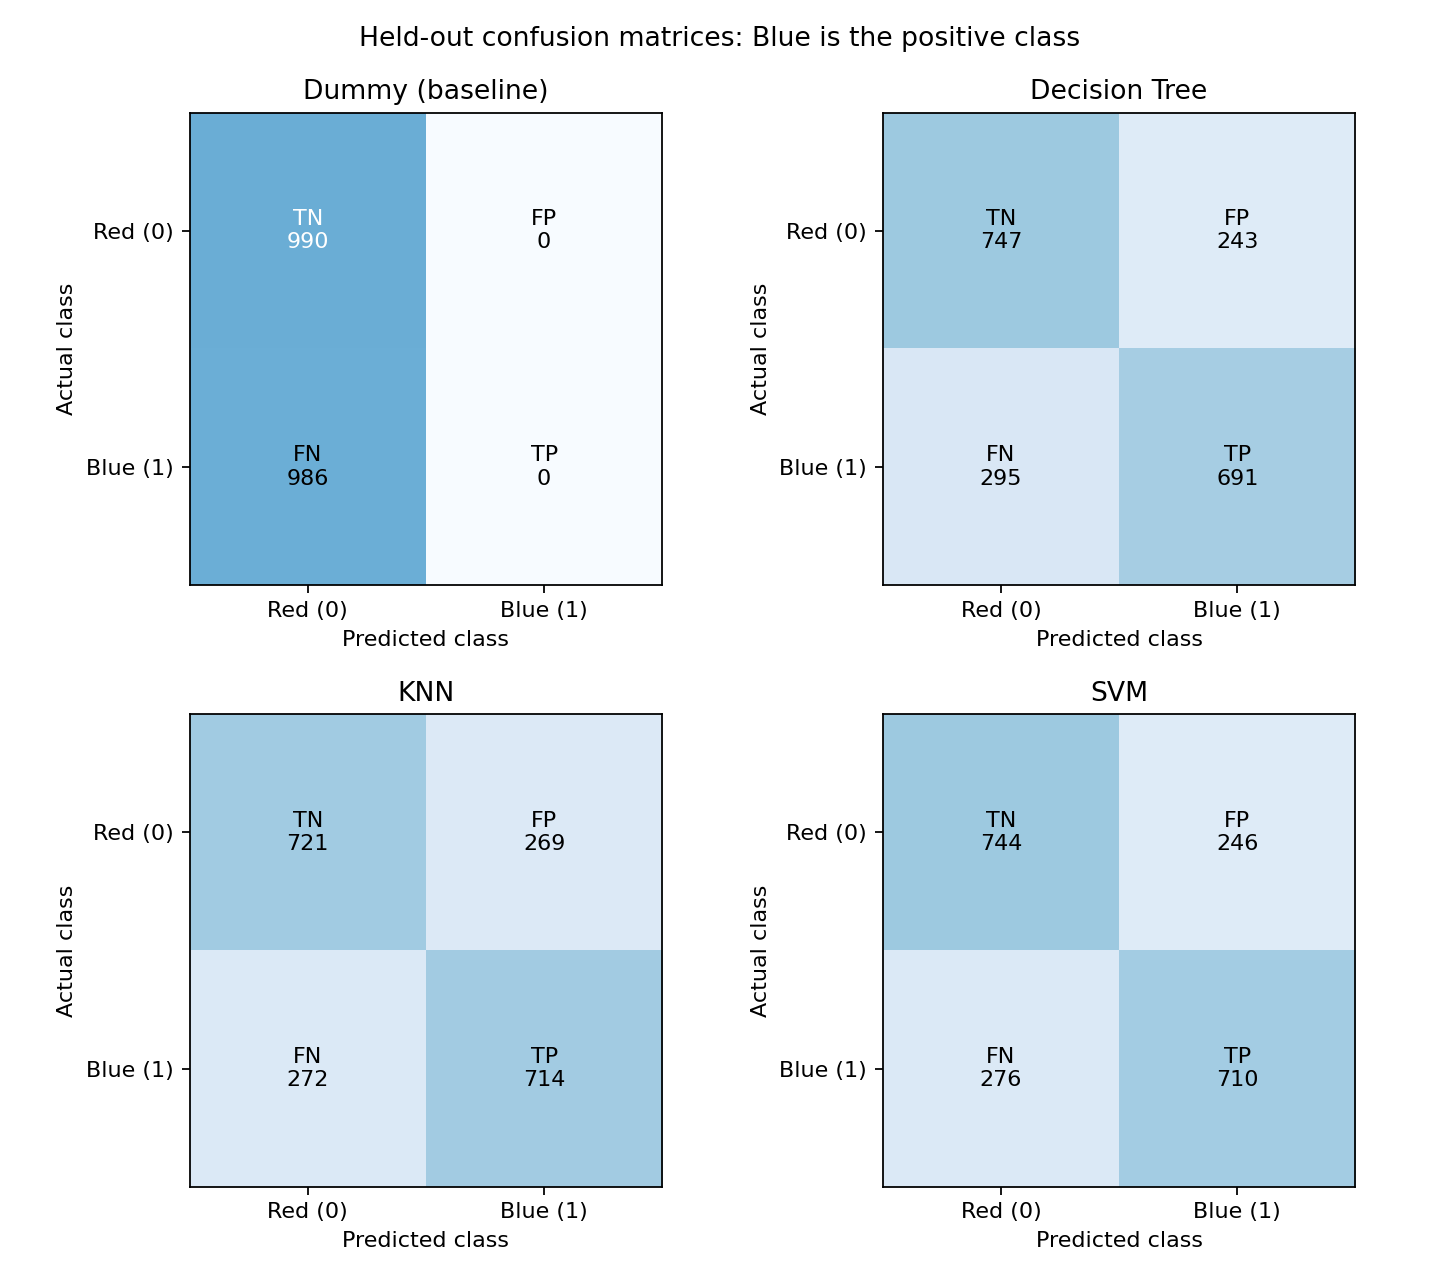

The SVM correctly predicts **1,454 of 1,976** winners and makes **522 errors**: 276 actual Blue wins are predicted as Red, while 246 Red wins are predicted as Blue. Dummy predicts Red throughout, correctly identifying all 990 Red wins and missing all 986 Blue wins. Its zero Blue precision, recall, and F1 are expected under the stated convention.

In [5]:
if complete:
    counts = pd.DataFrame.from_dict({name: {k: cm[k] for k in ("TN", "FP", "FN", "TP")}
                                    for name, cm in saved["confusion"].items()}, orient="index")
    counts = counts.loc[["dummy", "decision_tree", "knn", "svm"]]
    assert (counts.sum(axis=1) == 1976).all()
    display(counts.rename(index=MODEL_DISPLAY_NAMES).rename_axis("Model"))
    display(Image(filename=str(paths["figures"] / "confusion_matrices.png")))
    cm = saved["confusion"]["svm"]
    display(Markdown(
        f"The SVM correctly predicts **{cm['TN'] + cm['TP']:,} of 1,976** winners and "
        f"makes **{cm['FP'] + cm['FN']} errors**: {cm['FN']} actual Blue wins are predicted as Red, "
        f"while {cm['FP']} Red wins are predicted as Blue. Dummy predicts Red throughout, "
        "correctly identifying all 990 Red wins and missing all 986 Blue wins. "
        "Its zero Blue precision, recall, and F1 are expected under the stated convention."
    ))
else:
    print("Confusion matrices: pending final evaluation.")

## 6. ROC curves and AUC comparison

The true positive rate is Blue recall. The false positive rate is $FP/(FP+TN)$. Curves compare the ranking of the frozen models. The diagonal represents a random classifier with AUC 0.5. Thresholds along the curve are descriptive and were not used to change the operating point.

Dummy has constant class scores and therefore no ranking discrimination. The SVM uses `probability=False`: its decision margins are sufficient for ROC-AUC but are not calibrated win probabilities. AUC measures how often a randomly chosen Blue-win match receives a higher Blue score than a randomly chosen Red-win match, with ties receiving half credit.

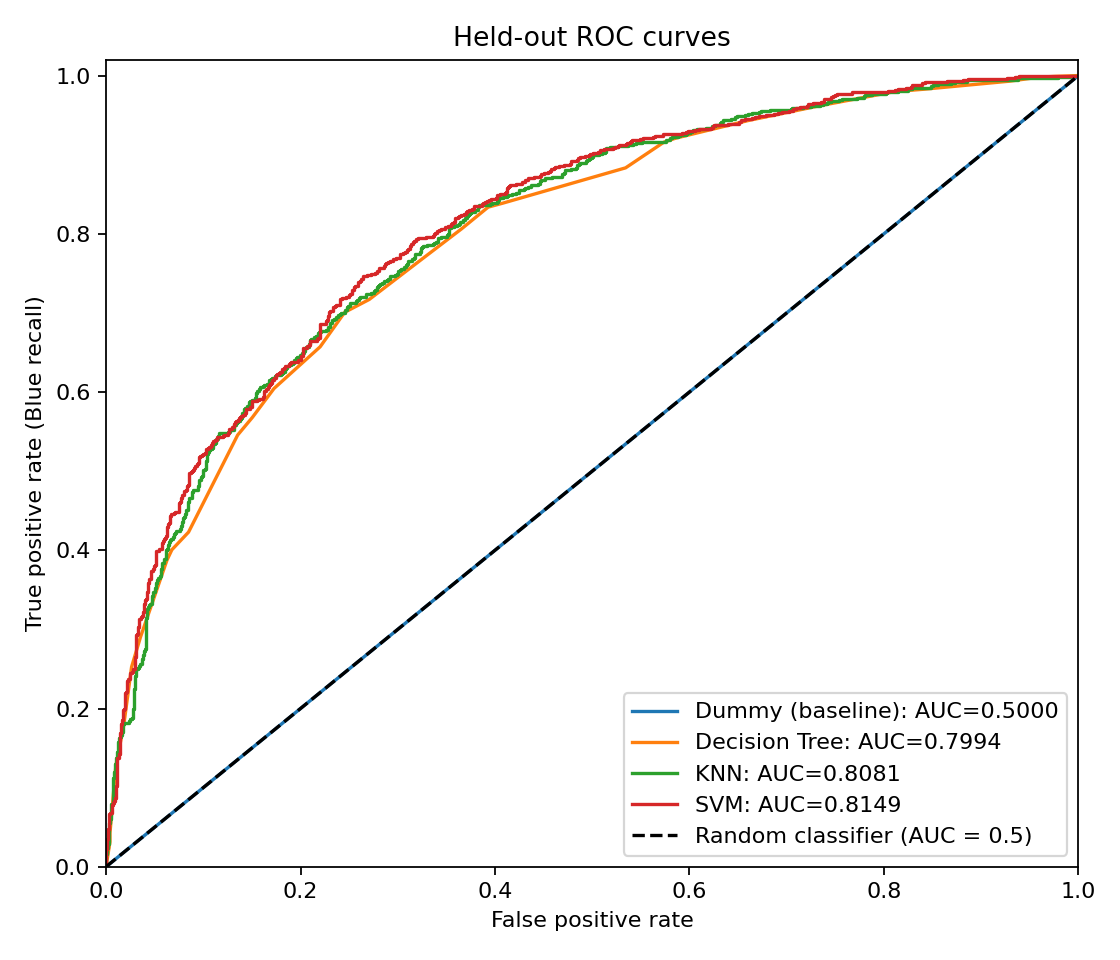

Observed ROC-AUC values are **Dummy (baseline): 0.5000**, **Decision Tree: 0.7994**, **KNN: 0.8081**, **SVM: 0.8149**. These are ranking estimates on this holdout, not calibrated individual probabilities.

In [6]:
if complete:
    display(Image(filename=str(paths["figures"] / "roc_curves.png")))
    display(Markdown(
        "Observed ROC-AUC values are " + ", ".join(
            f"**{MODEL_DISPLAY_NAMES[name]}: {saved['metrics'][name]['roc_auc']:.4f}**"
            for name in ["dummy", "decision_tree", "knn", "svm"]
        ) + ". These are ranking estimates on this holdout, not calibrated individual probabilities."
    ))
else:
    print("ROC curves: pending final evaluation.")

## 7. Descriptive comparison with nested cross-validation and Dummy

The following CV estimates were calculated in Part B using training records only. They are displayed as context, not as held-out results. Sample SD (`ddof=1`) describes variability across five outer folds and is not a confidence interval.

The final comparison reports each test metric next to its outer CV mean and SD, plus the test-minus-CV difference. It also reports differences from Dummy, with accuracy gains expressed in percentage points. The final inner search scores are not substituted for outer CV estimates. Small differences do not establish statistical significance. The SVM remains the selected family even if another model has a higher test metric.

,Model,Outer CV mean accuracy,Outer CV accuracy sample SD,Outer CV mean ROC-AUC,Outer CV ROC-AUC sample SD
0,Dummy (baseline),0.5009,0.0002,0.5000,0.0000
1,Decision Tree,0.7158,0.0206,0.7940,0.0132
2,KNN,0.7162,0.0145,0.7986,0.0130
3,SVM,0.7295,0.0167,0.8089,0.0136


,Model,Metric,Outer CV mean,Outer CV sample SD,Test value,Test minus CV mean,Test minus Dummy,Accuracy gain over Dummy (percentage points),Selected before test
0,Dummy (baseline),accuracy,0.5009,0.0002,0.5010,0.0001,0.0000,0.00,False
1,Dummy (baseline),precision,0.0000,0.0000,0.0000,0.0000,0.0000,Not applicable,False
2,Dummy (baseline),recall,0.0000,0.0000,0.0000,0.0000,0.0000,Not applicable,False
3,Dummy (baseline),f1,0.0000,0.0000,0.0000,0.0000,0.0000,Not applicable,False
4,Dummy (baseline),roc_auc,0.5000,0.0000,0.5000,0.0000,0.0000,Not applicable,False
5,Decision Tree,accuracy,0.7158,0.0206,0.7277,0.0119,0.2267,22.67,False
6,Decision Tree,precision,0.7216,0.0315,0.7398,0.0182,0.7398,Not applicable,False
7,Decision Tree,recall,0.7051,0.0441,0.7008,-0.0043,0.7008,Not applicable,False
8,Decision Tree,f1,0.7121,0.0212,0.7198,0.0077,0.7198,Not applicable,False
9,Decision Tree,roc_auc,0.7940,0.0132,0.7994,0.0054,0.2994,Not applicable,False


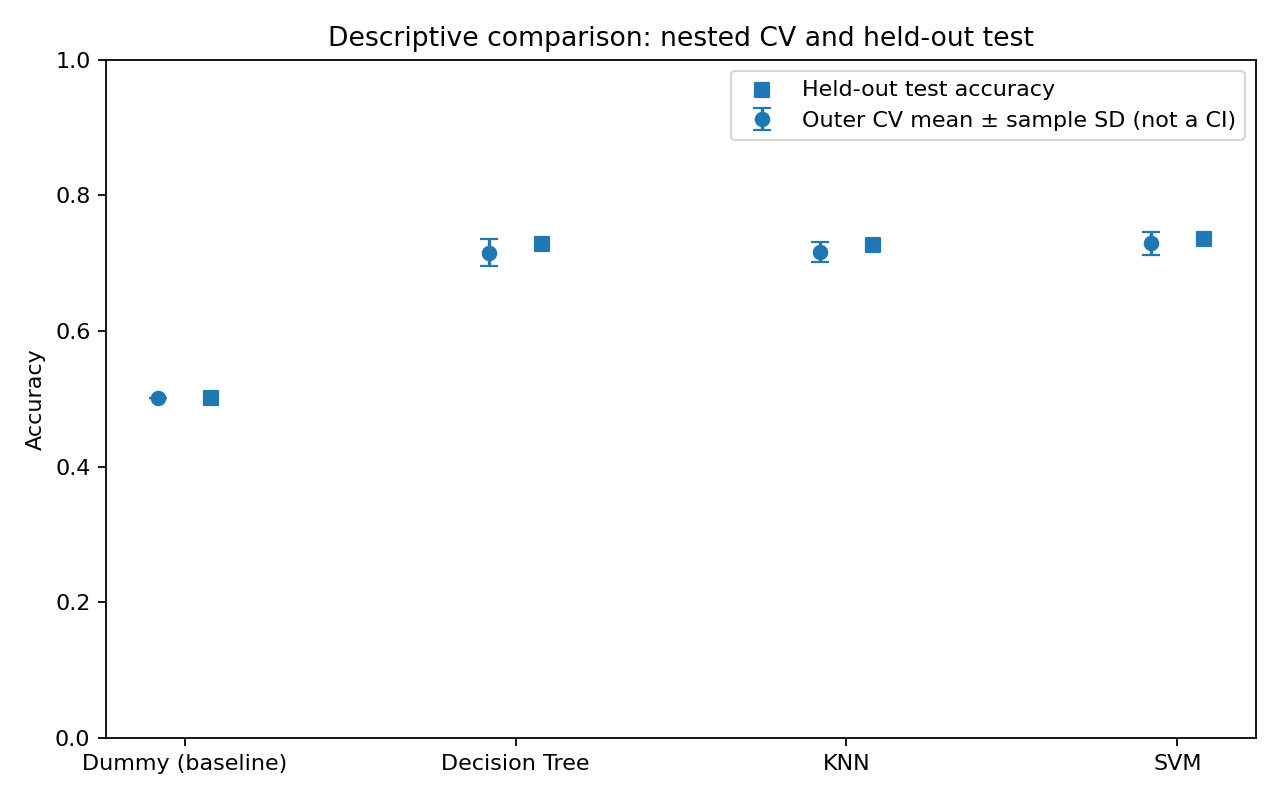

SVM accuracy is 0.7295 in outer CV (sample SD 0.0167) and 0.7358 on the test set: a descriptive difference of +0.64 percentage points. Its ROC-AUC changes from 0.8089 to 0.8149. These estimates are similar in magnitude, but this does not establish statistical equivalence, stability on future patches, or absence of overfitting. CV and test samples serve different roles.

In [7]:
cv_columns = ["model", "mean_accuracy", "std_accuracy", "mean_roc_auc", "std_roc_auc"]
cv_table = training["comparison"][cv_columns].copy()
cv_table["model"] = cv_table["model"].map(MODEL_DISPLAY_NAMES)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(cv_table.rename(columns={
        "model": "Model", "mean_accuracy": "Outer CV mean accuracy",
        "std_accuracy": "Outer CV accuracy sample SD", "mean_roc_auc": "Outer CV mean ROC-AUC",
        "std_roc_auc": "Outer CV ROC-AUC sample SD",
    }))
if complete:
    comparison = pd.DataFrame(saved["comparison"])[[
        "model", "metric", "outer_cv_mean", "outer_cv_sample_sd", "test_value",
        "test_minus_outer_cv_mean", "test_minus_dummy", "accuracy_gain_percentage_points",
        "selected_before_test",
    ]]
    comparison["model"] = comparison["model"].map(MODEL_DISPLAY_NAMES)
    comparison["accuracy_gain_percentage_points"] = comparison["accuracy_gain_percentage_points"].map(
        lambda value: "Not applicable" if pd.isna(value) else f"{value:.2f}"
    )
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(comparison.rename(columns={
            "model": "Model", "metric": "Metric", "test_value": "Test value",
            "outer_cv_mean": "Outer CV mean", "outer_cv_sample_sd": "Outer CV sample SD",
            "test_minus_outer_cv_mean": "Test minus CV mean", "test_minus_dummy": "Test minus Dummy",
            "accuracy_gain_percentage_points": "Accuracy gain over Dummy (percentage points)",
            "selected_before_test": "Selected before test",
        }))
    display(Image(filename=str(paths["figures"] / "cv_test_accuracy.png")))
    svm_cv = training["comparison"].set_index("model").loc["svm"]
    svm = saved["metrics"]["svm"]
    display(Markdown(
        f"SVM accuracy is {svm_cv['mean_accuracy']:.4f} in outer CV "
        f"(sample SD {svm_cv['std_accuracy']:.4f}) and {svm['accuracy']:.4f} on the test set: "
        f"a descriptive difference of {100 * (svm['accuracy'] - svm_cv['mean_accuracy']):+.2f} "
        f"percentage points. Its ROC-AUC changes from {svm_cv['mean_roc_auc']:.4f} "
        f"to {svm['roc_auc']:.4f}. These estimates are similar in magnitude, "
        "but this does not establish statistical equivalence, stability on future patches, "
        "or absence of overfitting. CV and test samples serve different roles."
    ))

## 8. Interpretation using the fitted StandardScaler

The saved model is

$$f(x)=b+\sum_j w_j\frac{x_j-\mu_j}{s_j},$$

where $\mu_j$ and $s_j$ were learned only from the 7,903 training matches. A positive coefficient increases the Blue decision score when that feature increases and other features are held fixed. The magnitude $|w_j|$ describes sensitivity to one training standard deviation. For discrete features, such a change may not correspond to a feasible single-game event.

In original units, $\beta_j=w_j/s_j$ and $b_{original}=b-\sum_j w_j\mu_j/s_j$. Both representations are verified against `decision_function` on artificial inputs. Neither raw-unit magnitudes across differently scaled features nor standardized magnitudes establish causal importance. Correlated gold, experience, kills, and assists can redistribute signs and magnitudes.

The table and chart below describe the already trained model and can be examined before held-out evaluation. They do not use test values or support new feature selection.

,Feature,Standardized coefficient,Absolute standardized coefficient,Training mean,Training scale,Original-unit coefficient
0,blueGoldDiff,1.123845,1.123845,22.457295,2459.386568,0.000457
1,blueExperienceDiff,0.415138,0.415138,-26.135645,1927.678458,0.000215
9,dragonsDiff,0.243173,0.243173,-0.049728,0.879092,0.276618
4,minionsDiff,-0.159640,0.159640,-0.685436,30.935697,-0.005160
2,killsDiff,-0.131435,0.131435,0.055422,4.203505,-0.031268
11,towersDestroyedDiff,-0.093446,0.093446,0.011008,0.327963,-0.284929
3,assistsDiff,-0.067275,0.067275,0.003796,5.768839,-0.011662
10,heraldsDiff,0.062119,0.062119,0.024295,0.589603,0.105357
8,firstBloodDiff,0.038807,0.038807,0.009743,0.999953,0.038809
6,wardsPlacedDiff,-0.032965,0.032965,-0.187650,25.773340,-0.001279


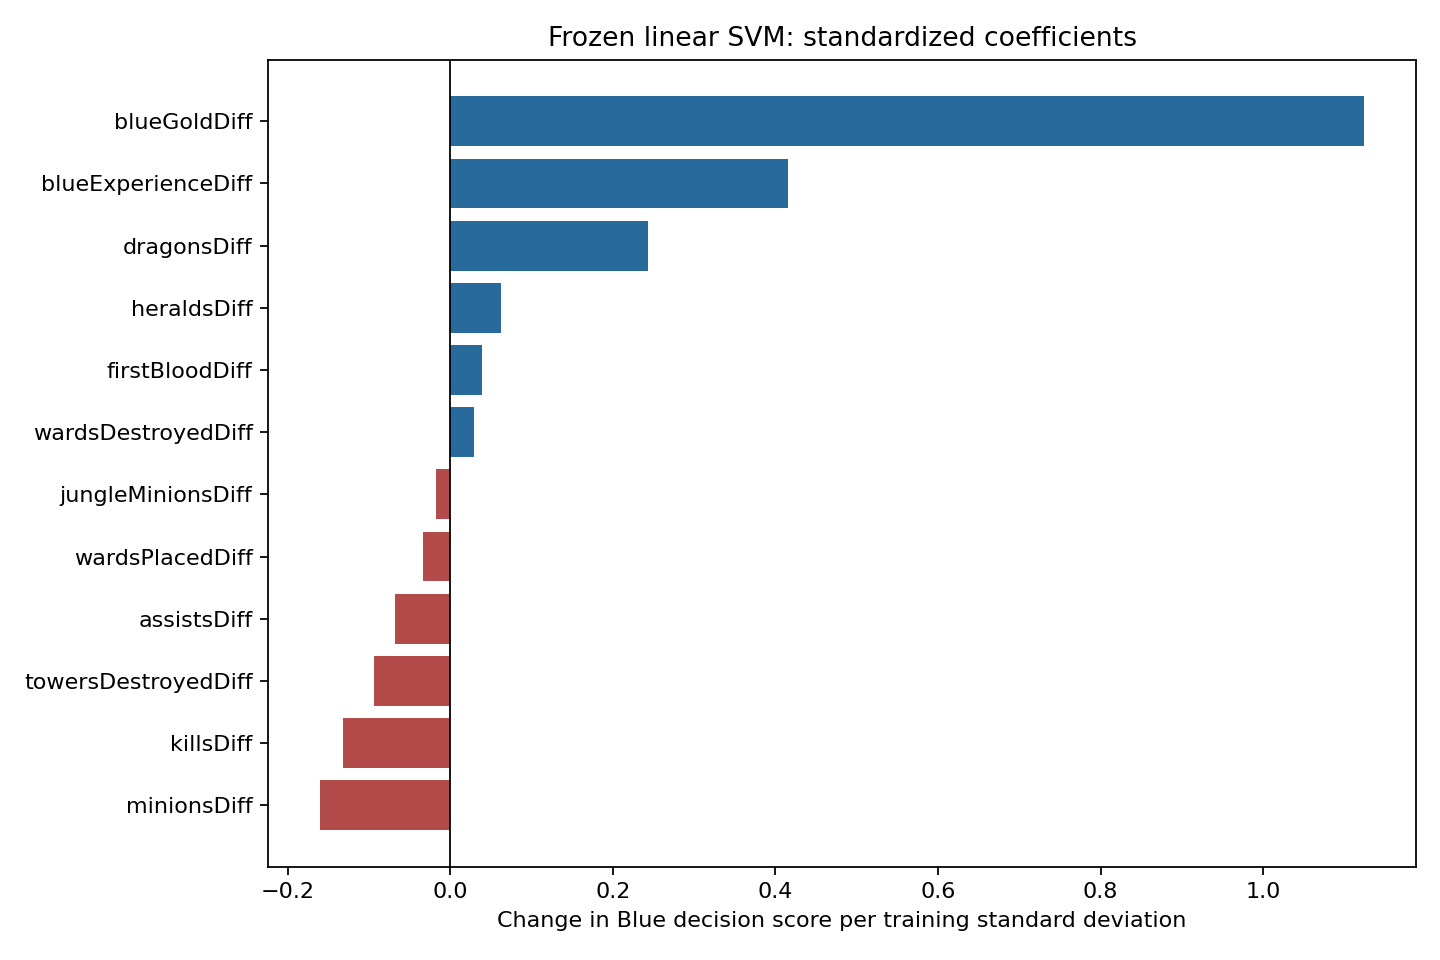

Largest absolute standardized sensitivities in the frozen model:
blueGoldDiff: +1.1238 decision-score units per training standard deviation.
blueExperienceDiff: +0.4151 decision-score units per training standard deviation.
dragonsDiff: +0.2432 decision-score units per training standard deviation.
Negative combat, farming, or tower coefficients are conditional on the other predictors; they do not imply harmful causal effects of gaining those resources.


In [8]:
coefficients = saved["coefficients"]
display(coefficients.sort_values("absolute_standardized_coefficient", ascending=False).rename(columns={
    "feature": "Feature", "standardized_coefficient": "Standardized coefficient",
    "absolute_standardized_coefficient": "Absolute standardized coefficient",
    "training_mean": "Training mean", "training_scale": "Training scale",
    "original_unit_coefficient": "Original-unit coefficient",
}).round(6))
display(Image(filename=str(paths["figures"] / "svm_standardized_coefficients.png")))
strongest = coefficients.sort_values("absolute_standardized_coefficient", ascending=False).head(3)
print("Largest absolute standardized sensitivities in the frozen model:")
for row in strongest.itertuples():
    print(f"{row.feature}: {row.standardized_coefficient:+.4f} decision-score units per training standard deviation.")
print("Negative combat, farming, or tower coefficients are conditional on the other predictors; they do not imply harmful causal effects of gaining those resources.")

## 9. Methodological limitations

1. A random holdout estimates performance within this Diamond sample. No transfer to other ranks, regions, or future patches is established.
2. Player identifiers, patch, collection date, and region metadata are unavailable. Independence across repeated players and temporal robustness cannot be established.
3. The observational feature set contains strongly correlated predictors. Coefficients do not identify causal interventions.
4. Suspicious ward counts are retained unchanged. Difference features omit absolute game tempo and can merge distinct tied objective states.
5. Selecting the model family using CV creates selection optimism. A single holdout also has sampling uncertainty; fold SD does not provide a test confidence interval.
6. KNN's `k=81` and SVM's `C=10` lie at grid boundaries. They remain frozen; final test results cannot justify further tuning.
7. SVM margins are uncalibrated. No probability calibration or threshold optimization is performed.
8. Inspecting four models on the holdout does not authorize choosing a new winner. The final inferential focus remains the SVM chosen in Part B.

## 10. Answer to the Research Question and reproducibility

The final answer is based on the SVM selected before independent evaluation, its observed performance relative to Dummy, and the remaining prediction errors. The conclusion applies to this original Diamond sample and the frozen twelve-feature representation.

The evaluation saved full-precision metrics, ROC coordinates, confusion counts, model provenance, and a local prediction cache. Displayed metric tables use four decimal places; accuracy percentages use two. Existing running, failed, or complete evaluations cannot be automatically overwritten. Plot regeneration and notebook execution consume saved outputs without repeating inference.

In [9]:
if complete:
    svm, dummy = saved["metrics"]["svm"], saved["metrics"]["dummy"]
    cm = saved["confusion"]["svm"]
    display(Markdown(
        "**Answer to the Research Question:** Yes, within this Diamond sample, statistics "
        "available after the first ten minutes support above-baseline prediction of the winning team. "
        f"The SVM selected through nested CV achieves **{svm['accuracy']:.2%} test accuracy** "
        f"and **{svm['roc_auc']:.4f} ROC-AUC** on 1,976 held-out matches. "
        f"This exceeds the majority-class baseline accuracy by "
        f"**{100 * (svm['accuracy'] - dummy['accuracy']):.2f} percentage points**. "
        f"It still makes {cm['FP'] + cm['FN']} errors, so this model does not predict every outcome correctly from the "
        "ten-minute state. These results establish neither causal effects nor generalization "
        "to other ranks, regions, or future patches."
    ))
    display(Markdown(
        "**Presentation summary:** The frozen linear SVM correctly predicts approximately "
        f"{100 * svm['accuracy']:.0f} out of 100 winners in this holdout. Gold, experience, and "
        "dragon advantages have the largest positive standardized coefficients. These are "
        "conditional predictive associations; SVM decision scores are not probabilities."
    ))
else:
    display(Markdown("**Final answer pending.** No test-based conclusion is available."))

**Answer to the Research Question:** Yes, within this Diamond sample, statistics available after the first ten minutes support above-baseline prediction of the winning team. The SVM selected through nested CV achieves **73.58% test accuracy** and **0.8149 ROC-AUC** on 1,976 held-out matches. This exceeds the majority-class baseline accuracy by **23.48 percentage points**. It still makes 522 errors, so this model does not predict every outcome correctly from the ten-minute state. These results establish neither causal effects nor generalization to other ranks, regions, or future patches.

**Presentation summary:** The frozen linear SVM correctly predicts approximately 74 out of 100 winners in this holdout. Gold, experience, and dragon advantages have the largest positive standardized coefficients. These are conditional predictive associations; SVM decision scores are not probabilities.